# Ocular dominance - group analysis

Five questions, one section each:

1. **Amblyopes:** in each ROI, does the fellow eye (FE) occupy more cortex than the amblyopic eye (AE)? *Hypothesis: yes.*
2. **Controls:** in each ROI, is there a difference between left (LE) and right eye (RE)? (no dominant / non-dominant eye available) *Hypothesis: no dominance.*
3. **Strength:** how strong is the fellow-eye dominance of the amblyopes (without letting vertices with a tiny preference count as a full vote)?
4. **Biases:** eye order, vertex selection (and circularity, tested before).
5. **Cross-validation between runs:** are the betas reproducible, i.e. not random (as in de Hollander et al. 2021 and Nasr et al. 2025)?

**Input:** OD images of `make_od_img.py` (β of each eye on the common pRF regressor, all 4 runs) + pRF derivatives / stats of each eye; for section 5 the per-run GLM sums cached by `od_glm_common_analysis.ipynb` (`Desktop/fig_od/od_glm_common_cache`). Nothing is written in the data folders.

**Vertex selection:** prf_analysis filters (`prf-analysis.yml`) applied to **both** eyes + positive pRF amplitude. **Vertex weight:** pRF R² (mean of both eyes).

**Conventions:** FE-LE = fellow eye (amblyopes) / left eye (controls); AE-RE = amblyopic eye / right eye. Bars = median across subjects, error bars = 25th-75th percentiles. Stars on the figures = test within each group (amblyopes: one-sided, in the direction of the hypothesis; controls: two-sided), FDR-corrected over the 8 ROIs: \* p < 0.05, \*\* < 0.01, \*\*\* < 0.001.

**Why non-parametric tests:** small groups (12 amblyopes, 8 controls), bounded measures (%) and a few atypical subjects: tests on ranks (Wilcoxon) do not assume normality and are robust to extreme subjects. **Why FDR:** the same test is repeated in 8 ROIs; Benjamini-Hochberg controls the proportion of false positives (less strict than Bonferroni).

In [1]:
# Stop warnings
import warnings
warnings.filterwarnings("ignore")

# General imports
import os
import sys
import numpy as np
import pandas as pd
from scipy import stats, integrate
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Personal imports
sys.path.append("{}/../../analysis_code/utils".format(os.getcwd()))
from settings_utils import load_settings
from pycortex_utils import set_pycortex_config_file, get_rois, load_surface_pycortex
from plot_utils import plotly_template

In [2]:
# Directories
main_dir = '/Users/uriel/disks/meso_shared'
project_dir = 'amblyo7T_prf'
pp_dir = '{}/{}/derivatives/pp_data'.format(main_dir, project_dir)
fig_dir = '/Users/uriel/Desktop/fig_od'
cache_dir = '/Users/uriel/Desktop/fig_od/od_glm_common_cache'       # per-run GLM sums (od_glm_common_analysis.ipynb)
os.makedirs(fig_dir, exist_ok=True)

# Settings
base_dir = os.path.abspath(os.path.join(os.getcwd(), "../../"))
settings = load_settings([os.path.join(base_dir, project_dir, f) for f in
                          ["settings.yml", "prf-analysis.yml", "figure-settings.yml"]])
analysis_info = settings[0]
patients = analysis_info['group-patient']
controls = analysis_info['group-control']
subjects = analysis_info['subjects']
maps_names_css = analysis_info['maps_names_css']
maps_names_css_stats = analysis_info['maps_names_css_stats']
maps_names_css_od = analysis_info['maps_names_css_od']

# Analysis
task = 'BarsBarsRingsWedges'
file_spec = '{}/{}/fsnative/prfmodel/prf_derivatives/{}_task-{}{}_hemi-{}_fmriprep_dct_psc_concat_prf-css_{}.func.gii'
rois_to_keep = ['V1', 'V2', 'V3', 'V4', 'V3A', 'V3B', 'LO1', 'LO2']
eyes = {'L': 'LeftEye', 'R': 'RightEye'}

# prf_analysis filters (applied to both eyes)
ecc_th = analysis_info['ecc_th']
size_th = analysis_info['size_th']
n_th = analysis_info['n_th']
rsqr_th = analysis_info['rsqr_th']
amp_th = analysis_info['prf_amp_th']
amp_th = amp_th['psc'] if isinstance(amp_th, dict) else amp_th
stats_th = analysis_info['stats_th']
p_name = 'corr_pvalue_5pt' if stats_th == 0.05 else 'corr_pvalue_1pt'

# Amblyopic eye of each patient
participants = pd.read_csv('{}/{}/participants.tsv'.format(main_dir, project_dir), sep='\t')
ambly_eye = {s: str(e).split(' ')[0] for s, e in zip(participants.participant_id, participants.amblyopic_eye)
             if str(e).split(' ')[0] in ('L', 'R')}

# Eye scanned first (read only: sourcedata/participant-mapping.md + participant_mapping.tsv)
src_dir = '{}/{}/sourcedata'.format(main_dir, project_dir)
mapping = pd.read_csv('{}/participant_mapping.tsv'.format(src_dir), sep='\t', dtype=str).dropna(subset=['initials'])
initials_to_sub = {i.strip(): b.strip() for i, b in zip(mapping.initials, mapping.bids_name)}
first_eye = {}
with open('{}/participant-mapping.md'.format(src_dir)) as f:
    for line in f:
        if 'eye first' in line:
            initials, txt = line.split(',', 1)
            first_eye[initials_to_sub[initials.strip()]] = 'L' if 'LEFT' in txt.upper() else 'R'

# Pycortex database (ROIs)
cortex_dir = '{}/{}/derivatives/pp_data/cortex'.format(main_dir, project_dir)
set_pycortex_config_file(cortex_dir)

## Load the data: measures per subject and ROI

- `pref_FE-LE` / `pref_AE-RE`: R²-weighted % of vertices preferring each eye, `100 · Σ R²·[β_FE > β_AE] / Σ R²` (questions 1 and 2);
- `od_index`: ROI OD index `(β̄_FE − β̄_AE) / (β̄_FE + β̄_AE)`, β̄ = R²-weighted mean β of the ROI (question 3);
- `pref_fe_sel` / `pref_ae_sel`: % FE-LE with the vertices selected on the filters of **one eye only** (FE-LE or AE-RE), and `rsq_fe` / `rsq_ae`: median pRF R² of each eye (question 4).

In [3]:
def select(d, st):
    """prf_analysis filters of one eye + positive pRF amplitude."""
    return ((d['prf_ecc'] >= ecc_th[0]) & (d['prf_ecc'] <= ecc_th[1])
            & (d['prf_size'] >= size_th[0]) & (d['prf_size'] <= size_th[1])
            & (d['prf_n'] >= n_th[0]) & (d['prf_n'] <= n_th[1])
            & (d['prf_rsq'] >= rsqr_th)
            & (d['amplitude'] >= amp_th[0]) & (d['amplitude'] <= amp_th[1]) & (d['amplitude'] > 0)
            & (st[maps_names_css_stats.index(p_name)] <= stats_th))


def pref_percent(b_fe, b_ae, w):
    return 100 * np.sum(w * (b_fe > b_ae)) / np.sum(w) if np.sum(w) > 0 else np.nan


rows, vertex_data = [], {}
for subject in subjects:
    group = 'patient' if subject in patients else 'control'

    # Betas of each eye (OD image of make_od_img.py)
    fns = [file_spec.format(pp_dir, subject, subject, task, '', hemi, 'od') for hemi in ['L', 'R']]
    if not all(os.path.isfile(fn) for fn in fns):
        print('{}: OD image missing, skipped'.format(subject))
        continue
    od_mat = load_surface_pycortex(L_fn=fns[0], R_fn=fns[1])['data_concat']
    beta = {'L': od_mat[maps_names_css_od.index('od_beta_le')], 'R': od_mat[maps_names_css_od.index('od_beta_re')]}

    # pRF derivatives and stats of each eye
    keep_eye, rsq_eye = {}, {}
    for e, eye in eyes.items():
        deriv = load_surface_pycortex(L_fn=file_spec.format(pp_dir, subject, subject, task, eye, 'L', 'deriv'),
                                      R_fn=file_spec.format(pp_dir, subject, subject, task, eye, 'R', 'deriv'))['data_concat']
        st = load_surface_pycortex(L_fn=file_spec.format(pp_dir, subject, subject, task, eye, 'L', 'stats'),
                                   R_fn=file_spec.format(pp_dir, subject, subject, task, eye, 'R', 'stats'))['data_concat']
        d = {name: deriv[i] for i, name in enumerate(maps_names_css)}
        keep_eye[e] = select(d, st)
        rsq_eye[e] = d['prf_rsq']
    keep = keep_eye['L'] & keep_eye['R']
    rsq = np.clip(np.nanmean([rsq_eye['L'], rsq_eye['R']], axis=0), 0, None)

    # FE-LE / AE-RE: amblyopes -> fellow / amblyopic eye, controls -> left / right eye
    fe, ae = ('R', 'L') if ambly_eye.get(subject) == 'L' else ('L', 'R')
    b_fe, b_ae = beta[fe], beta[ae]
    finite = np.isfinite(b_fe) & np.isfinite(b_ae)
    vertex_data[subject] = {'fe': fe, 'keep': keep & finite, 'rsq': rsq}

    rois = get_rois(subject=subject, surf_format='fsnative', rois_type='rois-mmp', mask=True, rois=None, hemis=None)
    for roi in rois_to_keep:
        mask = rois[roi] & keep & finite
        w = rsq[mask]
        if np.sum(w) == 0:
            continue
        m_fe, m_ae = np.sum(w * b_fe[mask]) / np.sum(w), np.sum(w * b_ae[mask]) / np.sum(w)
        mask_fe, mask_ae = rois[roi] & keep_eye[fe] & finite, rois[roi] & keep_eye[ae] & finite
        rows.append({'subject': subject, 'group': group, 'roi': roi, 'n_vertices': mask.sum(),
                     'fe_le_first': first_eye[subject] == fe,
                     'pref_FE-LE': pref_percent(b_fe[mask], b_ae[mask], w),
                     'pref_AE-RE': pref_percent(b_ae[mask], b_fe[mask], w),
                     'beta_fe': m_fe, 'beta_ae': m_ae,
                     'od_index': (m_fe - m_ae) / (m_fe + m_ae) if (m_fe > 0) & (m_ae > 0) else np.nan,
                     'pref_fe_sel': pref_percent(b_fe[mask_fe], b_ae[mask_fe], rsq[mask_fe]),
                     'pref_ae_sel': pref_percent(b_fe[mask_ae], b_ae[mask_ae], rsq[mask_ae]),
                     'rsq_fe': np.nanmedian(rsq_eye[fe][mask]), 'rsq_ae': np.nanmedian(rsq_eye[ae][mask])})
    print('{}: done'.format(subject))
df_subjects = pd.DataFrame(rows)
df_subjects.groupby(['group', 'roi'])[['n_vertices', 'pref_FE-LE', 'od_index']].median().unstack('group').reindex(rois_to_keep).round(3)

sub-01: done
sub-02: done
sub-03: done
sub-04: done
sub-05: done
sub-06: done
sub-07: done
sub-08: done
sub-09: done
sub-10: done
sub-11: done
sub-12: done
sub-13: done
sub-14: done
sub-16: done
sub-17: done
sub-18: done
sub-19: done
sub-20: done
sub-21: done


n_vertices         pref_FE-LE         od_index        
group    control patient    control patient  control patient
roi                                                         
V1        5107.0  4320.5     51.398  57.927    0.001   0.020
V2        4681.5  4117.5     56.214  62.645    0.018   0.091
V3        3202.5  2960.0     56.632  69.918    0.023   0.131
V4        2646.0  2454.5     57.800  71.459    0.028   0.111
V3A        784.5  1000.5     53.220  70.811   -0.003   0.129
V3B        321.0   509.0     46.095  83.305   -0.014   0.109
LO1        485.5   429.0     56.755  78.412    0.002   0.140
LO2        457.0   292.0     72.801  71.382    0.093   0.113

## Statistical tools and figure functions

- `within_tests`: per ROI, Wilcoxon signed-rank test of each group against the value of no preference (`h0`), FDR over the 8 ROIs; for the controls also the **Bayes factor BF01** (see question 2).
- `bar_figure`: figures in the style of the other pRF figures (plotly, one subplot per ROI, stars above each group).

In [4]:
def bh_fdr(p):
    """Benjamini-Hochberg FDR correction."""
    p = np.asarray(p, float)
    o = np.argsort(p)
    q = p[o] * len(p) / (np.arange(len(p)) + 1)
    q = np.minimum.accumulate(q[::-1])[::-1]
    out = np.empty_like(q)
    out[o] = np.minimum(q, 1)
    return out


def stars(p):
    return '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else ''


def bf10_ttest(x, h0=0, r=np.sqrt(2) / 2):
    """JZS Bayes factor BF10 of a one-sample t-test (Rouder et al. 2009), Cauchy prior of scale r on the effect size."""
    x = np.asarray(x, float)
    x = x[np.isfinite(x)] - h0
    n, v = x.size, x.size - 1
    t = x.mean() / (x.std(ddof=1) / np.sqrt(n))
    null = (1 + t ** 2 / v) ** (-(v + 1) / 2)
    alt = integrate.quad(lambda g: (1 + n * g * r ** 2) ** -0.5
                         * (1 + t ** 2 / ((1 + n * g * r ** 2) * v)) ** (-(v + 1) / 2)
                         * (2 * np.pi) ** -0.5 * g ** -1.5 * np.exp(-1 / (2 * g)), 0, np.inf)[0]
    return alt / null


def within_tests(df, value, h0, alt_patient='greater', alt_control='two-sided'):
    """Per ROI: Wilcoxon of each group vs h0 (FDR over the ROIs) + Bayes factor BF01 of the controls."""
    rows = []
    for roi in rois_to_keep:
        d = df[df.roi == roi]
        vp, vc = d[d.group == 'patient'][value].dropna(), d[d.group == 'control'][value].dropna()
        rows.append({'roi': roi, 'median_patients': vp.median(), 'median_controls': vc.median(),
                     'p_patients': stats.wilcoxon(vp - h0, alternative=alt_patient).pvalue,
                     'p_controls': stats.wilcoxon(vc - h0, alternative=alt_control).pvalue,
                     'BF01_controls': 1 / bf10_ttest(vc, h0)})
    s = pd.DataFrame(rows).set_index('roi')
    s['p_patients_fdr'] = bh_fdr(s.p_patients)
    s['p_controls_fdr'] = bh_fdr(s.p_controls)
    return s


# Figure settings (as the other pRF figures)
template_specs = dict(axes_color="rgba(0, 0, 0, 1)", axes_width=2, axes_font_size=15,
                      bg_col="rgba(255, 255, 255, 1)", font='Arial', title_font_size=15, rois_plot_width=1.5)
fig_template = plotly_template(template_specs)
roi_colors_rgb = analysis_info['roi_colors']
fig_margin = analysis_info['rois_fig_margin']
bar_width = analysis_info['rois_bar_width']
rois_plot_height = analysis_info['rois_plot_height']
rois_hor_spacing = 50
ctrl_color = 'rgb(150,150,150)'
groups = ['patient', 'control']
group_labels = {'patient': 'Amblyopes', 'control': 'Controls'}
cols = len(rois_to_keep)
fig_height = rois_plot_height * 2 + fig_margin[1] + fig_margin[3]
fig_width = bar_width * 4 * cols + fig_margin[0] + fig_margin[2] + (rois_hor_spacing * (cols - 1))
hor_spacing = rois_hor_spacing / (fig_width - fig_margin[0] - fig_margin[2])


def bar_figure(df, values, s, y_title, y_ticks, tick_fmt, fn_out, legends=None, patterns=None):
    """Median and 25-75 percentiles per group and ROI; stars = within-group test of s (FDR)."""
    patterns = patterns or [''] * len(values)
    y_step = (y_ticks[-1] - y_ticks[0]) * 0.05
    fig = make_subplots(rows=1, cols=cols, subplot_titles=rois_to_keep, horizontal_spacing=hor_spacing)
    for col_idx, roi in enumerate(rois_to_keep, start=1):
        d = df[df.roi == roi]
        top = {group: -np.inf for group in groups}
        for value, pattern in zip(values, patterns):
            med, p25, p75 = [], [], []
            for group in groups:
                v = d[d.group == group][value].dropna()
                med.append(v.median()); p25.append(np.nanpercentile(v, 25)); p75.append(np.nanpercentile(v, 75))
                top[group] = max(top[group], np.nanpercentile(v, 75), v.median(), 0)
            med, p25, p75 = np.array(med), np.array(p25), np.array(p75)
            fig.add_trace(go.Bar(x=[group_labels[g] for g in groups], y=med, offsetgroup=value,
                                 marker=dict(color=[roi_colors_rgb[roi], ctrl_color],
                                             pattern=dict(shape=pattern, fgcolor='rgba(0,0,0,1)',
                                                          bgcolor='rgba(0,0,0,0)', size=8)),
                                 error_y=dict(type='data', array=p75 - med, arrayminus=med - p25, visible=True,
                                              thickness=2, width=0, color='rgba(0,0,0,1)'),
                                 showlegend=False),
                          row=1, col=col_idx)
        xref, yref = 'x{}'.format('' if col_idx == 1 else col_idx), 'y{}'.format('' if col_idx == 1 else col_idx)
        for x_pos, group in enumerate(groups):
            p = s.loc[roi, 'p_{}_fdr'.format('patients' if group == 'patient' else 'controls')]
            fig.add_annotation(x=x_pos, y=top[group] + y_step / 2, xref=xref, yref=yref, text=stars(p),
                               showarrow=False, font=dict(size=16, color='black'), yanchor='bottom')
        fig.add_shape(type='line', x0=0, x1=0, y0=y_ticks[0], y1=y_ticks[-1], xref='{} domain'.format(xref), yref=yref,
                      line=dict(color=template_specs['axes_color'], width=template_specs['axes_width']))
    if legends:
        for legend, pattern in zip(legends, patterns):
            fig.add_trace(go.Bar(x=[None], y=[None], name=legend,
                                 marker=dict(color='rgba(128,128,128,1)',
                                             pattern=dict(shape=pattern, fgcolor='rgba(0,0,0,1)',
                                                          bgcolor='rgba(0,0,0,0.3)', size=8)),
                                 showlegend=True), row=1, col=1)
    fig.update_xaxes(showline=True, ticklen=0, linecolor='rgba(255,255,255,0)', tickangle=0)
    fig.update_yaxes(showline=False, range=[y_ticks[0], y_ticks[-1] + 3 * y_step], tickvals=y_ticks,
                     ticktext=[tick_fmt.format(t) for t in y_ticks], showticklabels=True)
    fig.update_yaxes(title_text=y_title, row=1, col=1)
    fig.update_layout(barmode='group', bargap=0.3, bargroupgap=0.05, height=fig_height, width=fig_width,
                      template=fig_template,
                      legend=dict(orientation='h', font_family=template_specs['font'],
                                  font_size=template_specs['axes_font_size'], x=1, y=1.15, xanchor='right',
                                  yanchor='bottom', bgcolor='rgba(0,0,0,0)', traceorder='normal', itemwidth=30),
                      margin_l=fig_margin[0], margin_t=fig_margin[1] + 40, margin_r=fig_margin[2], margin_b=fig_margin[3])
    fig.show()
    fig.write_image('{}/{}.pdf'.format(fig_dir, fn_out))


def nice_ticks(values, step):
    lo = min(0, np.floor(np.nanmin(values) / step) * step)
    hi = max(step, np.ceil(np.nanmax(values) / step) * step)
    return np.round(np.arange(lo, hi + step / 2, step), 3)

## Questions 1 and 2: how much cortex prefers each eye

**Measure:** R²-weighted % of vertices preferring the FE-LE eye (`pref_FE-LE`). 50 % = no preference.

**Question 1 (amblyopes):** Wilcoxon signed-rank test of `pref_FE-LE` vs 50 %, **one-sided** (hypothesis FE > AE), FDR over the 8 ROIs.

**Question 2 (controls):** the hypothesis is the **absence** of dominance. A non-significant test does not show an absence of effect (with 8 subjects, it may only reflect a lack of power). Two complementary results:

- Wilcoxon signed-rank test vs 50 %, two-sided (is there a left or right eye preference?);
- **Bayes factor BF01** (JZS one-sample t-test, Cauchy prior r = 0.707): how many times the data are more likely under "no preference" than under "preference". BF01 > 3 = moderate evidence for no dominance, 1-3 = anecdotal, < 1 = favours a dominance.

Each vertex votes by the sign of its preference: a vertex with a tiny preference counts as much as a vertex with a clear one. This makes the measure conservative (random votes pull it towards 50 %) but says nothing about the strength: see question 3.

In [5]:
s_pref = within_tests(df_subjects, 'pref_FE-LE', 50)
print('% of vertices preferring FE-LE (H0 = 50 %): amblyopes one-sided, controls two-sided')
s_pref[['median_patients', 'p_patients_fdr', 'median_controls', 'p_controls_fdr', 'BF01_controls']].round(3)

% of vertices preferring FE-LE (H0 = 50 %): amblyopes one-sided, controls two-sided


,median_patients,p_patients_fdr,median_controls,p_controls_fdr,BF01_controls
roi,,,,,
V1,57.927,0.013,51.398,0.615,1.870
V2,62.645,0.014,56.214,0.615,1.480
V3,69.918,0.013,56.632,0.615,2.099
V4,71.459,0.007,57.800,0.615,1.923
V3A,70.811,0.006,53.220,1.000,2.951
V3B,83.305,0.015,46.095,0.732,2.456
LO1,78.412,0.007,56.755,0.615,1.853
LO2,71.382,0.032,72.801,0.615,1.121


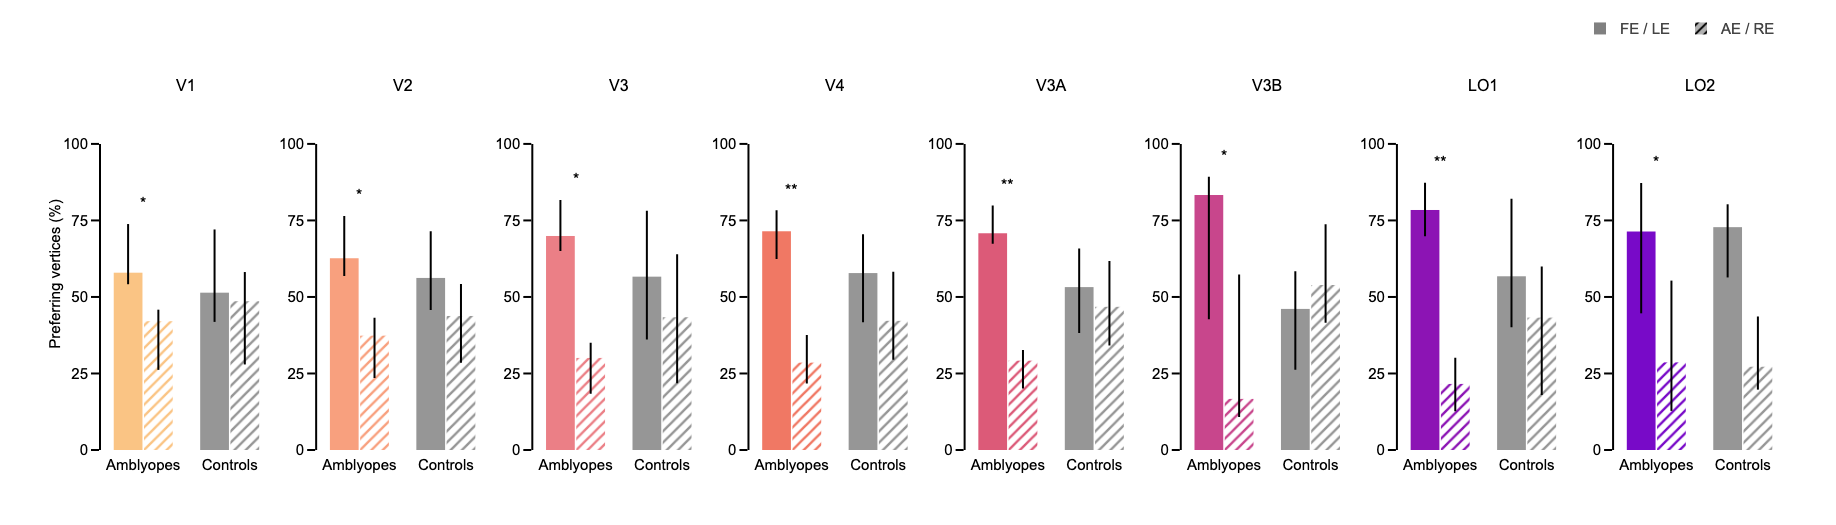

In [6]:
bar_figure(df_subjects, ['pref_FE-LE', 'pref_AE-RE'], s_pref, 'Preferring vertices (%)', np.linspace(0, 100, 5), '{:.0f}',
           'od_q1-2_pref_percent', legends=['FE / LE', 'AE / RE'], patterns=['', '/'])

## Question 3: strength of the dominance

**Measure (main figure):** **fellow-eye response advantage** = how much more the FE-LE eye responds than the AE-RE eye, in %: `100 · (β̄_FE / β̄_AE − 1)`, with β̄ the R²-weighted mean β of the ROI (betas averaged **before** the ratio, so vertices with a tiny preference barely matter). 0 % = both eyes respond equally; +25 % = the fellow eye responds 1.25 times more. This is the same information as the ROI OD index `(β̄_FE − β̄_AE) / (β̄_FE + β̄_AE)` (table below), in a directly readable unit.

**Test:** Wilcoxon signed-rank vs 0 (amblyopes one-sided, controls two-sided + BF01), FDR over the ROIs.

In [7]:
df_subjects['fe_advantage'] = np.where((df_subjects.beta_fe > 0) & (df_subjects.beta_ae > 0),
                                       100 * (df_subjects.beta_fe / df_subjects.beta_ae - 1), np.nan)
s_adv = within_tests(df_subjects, 'fe_advantage', 0)
s_od = within_tests(df_subjects, 'od_index', 0)
print('Fellow-eye response advantage, % (H0 = 0): amblyopes one-sided, controls two-sided')
print(s_adv[['median_patients', 'p_patients_fdr', 'median_controls', 'p_controls_fdr', 'BF01_controls']].round(3))
print('\nOD index (H0 = 0)')
print(s_od[['median_patients', 'p_patients_fdr', 'median_controls', 'p_controls_fdr', 'BF01_controls']].round(3))

Fellow-eye response advantage, % (H0 = 0): amblyopes one-sided, controls two-sided
     median_patients  p_patients_fdr  median_controls  p_controls_fdr  \
roi                                                                     
V1          4.144000           0.024         0.301000           0.964   
V2         20.063999           0.007         3.656000           0.964   
V3         30.038000           0.007         4.839000           0.964   
V4         25.080999           0.007         5.791000           0.964   
V3A        29.695999           0.007        -0.574000           0.964   
V3B        24.445999           0.046        -2.736000           1.000   
LO1        32.673000           0.007         0.427000           0.964   
LO2        25.593000           0.023        20.603001           0.625   

     BF01_controls  
roi                 
V1           2.262  
V2           1.813  
V3           1.915  
V4           1.727  
V3A          2.466  
V3B          2.974  
LO1          2.301

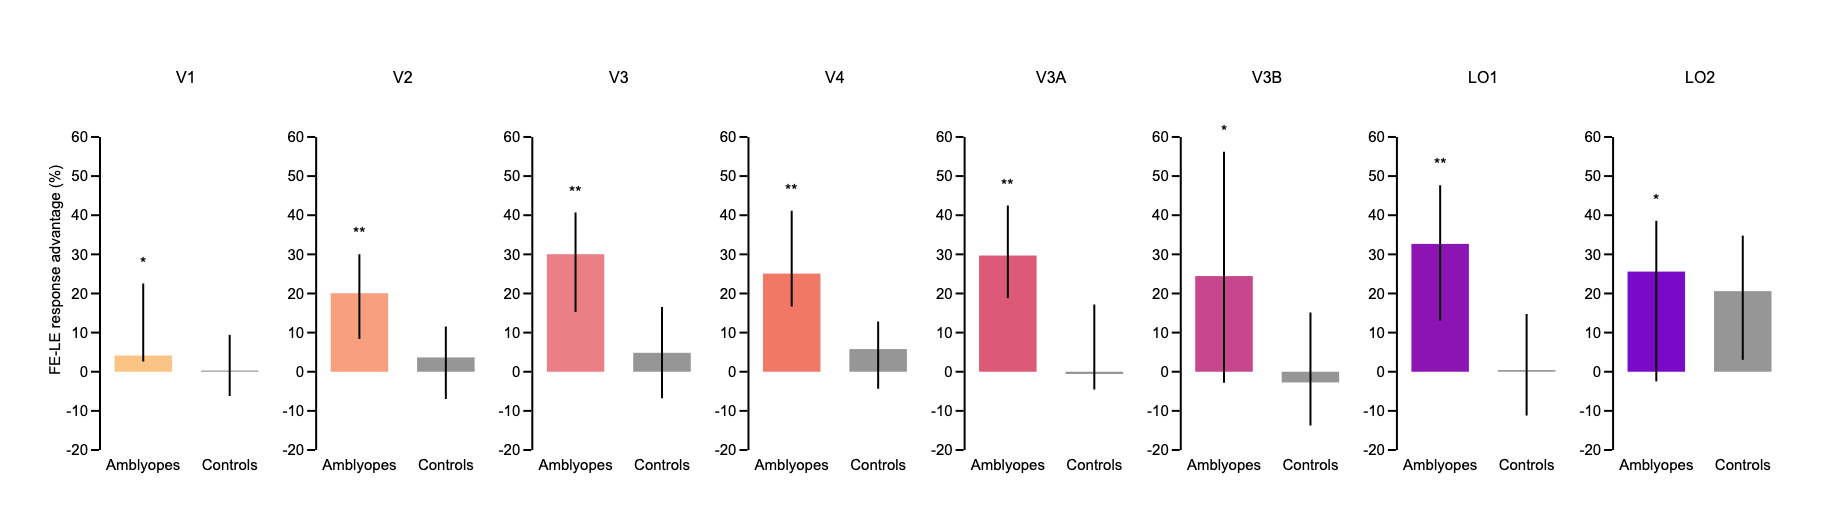

In [8]:
bar_figure(df_subjects, ['fe_advantage'], s_adv, 'FE-LE response advantage (%)',
           nice_ticks(df_subjects.groupby(['group', 'roi']).fe_advantage.quantile([0.25, 0.75]), 10), '{:.0f}',
           'od_q3_fe_advantage')

## Question 4: biases

**Eye order.** Each eye was scanned in separate runs, so a global change between the two halves of the session (vigilance, fatigue, adaptation) could look like a dominance. The order was alternated across subjects but is not balanced between fellow and amblyopic eye (amblyopes: FE first in 4, AE first in 8).

- amblyopes: % FE and OD index of the subjects with FE scanned first vs second (Mann-Whitney, two-sided). If the dominance came from the order, it would differ between these subgroups;
- controls: % of vertices preferring the eye scanned **first** vs 50 % (Wilcoxon, two-sided): a direct estimate of the order effect without amblyopia.

**Vertex selection.** Vertices are kept when the pRF fits of **both** eyes pass the filters. If the amblyopic eye is fitted worse, vertices where it responds could be lost. Checks in the amblyopes: (1) median pRF R² of FE vs AE (paired Wilcoxon); (2) % FE recomputed with the vertices selected on the fellow eye only and on the amblyopic eye only (Wilcoxon vs 50 %, one-sided). If the dominance holds when selecting on the amblyopic eye alone, the selection does not create it.

**Circularity** (each eye's prediction was fitted on that eye's data) was tested in `od_glm_common_analysis.ipynb` (section 11): regressing each eye on the **other** eye's prediction gives the same results (subject correlation 0.98-0.99 in V1-V3).

In [9]:
rows = []
for roi in rois_to_keep:
    d = df_subjects[df_subjects.roi == roi]
    pat, ctrl = d[d.group == 'patient'], d[d.group == 'control']
    first_pref = np.where(ctrl.fe_le_first, ctrl['pref_FE-LE'], ctrl['pref_AE-RE'])
    rows.append({'roi': roi,
                 # Eye order
                 'pat_pref_FE_first': pat[pat.fe_le_first]['pref_FE-LE'].median(),
                 'pat_pref_FE_second': pat[~pat.fe_le_first]['pref_FE-LE'].median(),
                 'p_order_pref': stats.mannwhitneyu(pat[pat.fe_le_first]['pref_FE-LE'], pat[~pat.fe_le_first]['pref_FE-LE']).pvalue,
                 'p_order_od': stats.mannwhitneyu(pat[pat.fe_le_first].od_index.dropna(), pat[~pat.fe_le_first].od_index.dropna()).pvalue,
                 'ctrl_pref_first_eye': np.median(first_pref),
                 'p_ctrl_first_eye': stats.wilcoxon(first_pref - 50).pvalue,
                 # Vertex selection
                 'pat_rsq_fe': pat.rsq_fe.median(), 'pat_rsq_ae': pat.rsq_ae.median(),
                 'p_rsq_fe_vs_ae': stats.wilcoxon(pat.rsq_fe, pat.rsq_ae).pvalue,
                 'pat_pref_sel_fe': pat.pref_fe_sel.median(),
                 'p_sel_fe': stats.wilcoxon(pat.pref_fe_sel - 50, alternative='greater').pvalue,
                 'pat_pref_sel_ae': pat.pref_ae_sel.median(),
                 'p_sel_ae': stats.wilcoxon(pat.pref_ae_sel - 50, alternative='greater').pvalue})
bias = pd.DataFrame(rows).set_index('roi')
for col in ['p_order_pref', 'p_order_od', 'p_ctrl_first_eye', 'p_rsq_fe_vs_ae', 'p_sel_fe', 'p_sel_ae']:
    bias[col + '_fdr'] = bh_fdr(bias[col])
print('Eye order')
print(bias[['pat_pref_FE_first', 'pat_pref_FE_second', 'p_order_pref_fdr', 'p_order_od_fdr',
            'ctrl_pref_first_eye', 'p_ctrl_first_eye_fdr']].round(3))
print('\nVertex selection (amblyopes)')
print(bias[['pat_rsq_fe', 'pat_rsq_ae', 'p_rsq_fe_vs_ae_fdr', 'pat_pref_sel_fe', 'p_sel_fe_fdr',
            'pat_pref_sel_ae', 'p_sel_ae_fdr']].round(3))

Eye order
     pat_pref_FE_first  pat_pref_FE_second  p_order_pref_fdr  p_order_od_fdr  \
roi                                                                            
V1              65.492              57.927               1.0           0.760   
V2              66.853              62.645               1.0           0.780   
V3              69.634              69.918               1.0           0.737   
V4              71.533              71.459               1.0           0.735   
V3A             75.056              70.378               1.0           0.735   
V3B             80.899              83.305               1.0           0.933   
LO1             79.616              78.412               1.0           0.735   
LO2             51.967              77.296               1.0           0.735   

     ctrl_pref_first_eye  p_ctrl_first_eye_fdr  
roi                                             
V1                43.428                 0.612  
V2                40.955                 0

## Question 5: cross-validation between runs

**Idea (as the two papers):** split the 4 runs into two independent halves, **both eyes in each half**, compute β_FE and β_AE in each half, and check that what is measured in one half is found again in the other. If the betas were random, nothing would replicate. Nasr et al. correlate the OD maps of two sessions vertex by vertex; de Hollander et al. correlate the z maps of the two halves of the session and classify voxels on some runs and test them on left-out runs.

**Splits:** the three ways to split the 4 runs in 2 + 2 (`Bars01+Rings | Bars02+Wedges`, `Bars01+Wedges | Bars02+Rings`, `Bars | Rings+Wedges`); every measure is averaged over the three splits (and over both directions A → B, B → A when it is not symmetric).

**Measures per subject and ROI** (same vertices and R² weights as above):

| measure | definition | no consistency (random betas) | question |
|---|---|---|---|
| `r_maps` | Spearman correlation across vertices of β_FE − β_AE between the two halves | 0 | are the maps reproducible? (as Nasr / de Hollander) |
| `agreement` | R²-weighted % of vertices preferring the same eye in both halves | 50 % | is the preferred eye of a vertex stable? |
| `pref_fe_cv` | among the vertices with the **same** preference in both halves, % preferring FE-LE | 50 % | question 1 with only reproducible votes: vertices with a random tiny preference fall out |
| `selectivity_cv` | `Σ w·sign(β_FE − β_AE)_A·(β_FE − β_AE)_B / Σ w·(β_FE + β_AE)_B`: the eye difference in one half, signed by the preference found in the other half | 0 | cross-validated strength of the ocular preference (whatever the eye): noise averages to 0 instead of inflating it |
| `pref_half_r` | correlation **across subjects** of the % FE-LE computed in each half | 0 | are the differences between subjects reliable? |

**Tests:** Wilcoxon signed-rank vs the "random" value, one-sided (`greater`) in **both** groups (reproducible maps are expected in controls too), FDR over the ROIs; `pref_fe_cv`: same tests as question 1 (amblyopes one-sided, controls two-sided + BF01).

**Note:** the betas of the halves come from the per-run sums of `od_glm_common_analysis.ipynb` (regressor z-scored per run instead of over the concatenation: within a run both eyes share the same regressor, so the sign and the ratios of the betas are unchanged). **Limit:** both halves contain runs of each eye scanned in the same order, so a systematic order effect would also replicate: the cross-validation shows that the betas are not random, the order is tested in question 4.

In [10]:
splits = {'Bars01+Rings | Bars02+Wedges': ([0, 2], [1, 3]),
          'Bars01+Wedges | Bars02+Rings': ([0, 3], [1, 2]),
          'Bars | Rings+Wedges': ([0, 1], [2, 3])}

rows = []
for subject in df_subjects.subject.unique():
    cache_fn = '{}/{}_od-glm-common_runs.npz'.format(cache_dir, subject)
    if not os.path.isfile(cache_fn):
        print('{}: no per-run cache, skipped'.format(subject))
        continue
    cache = np.load(cache_fn)
    vd = vertex_data[subject]
    vert = cache['vertex']
    keep, w_all, roi_names = vd['keep'][vert], vd['rsq'][vert], cache['roi']
    fe_i, ae_i = (1, 0) if vd['fe'] == 'R' else (0, 1)                      # cache eye order: 0 = left, 1 = right

    for split, (runs_A, runs_B) in splits.items():
        halves = []
        for runs in (runs_A, runs_B):
            with np.errstate(divide='ignore', invalid='ignore'):
                b = cache['sxy_common'][:, runs].sum(axis=1) / cache['sxx_common'][runs].sum(axis=0)
            halves.append((b[fe_i], b[ae_i]))
        (fe_A, ae_A), (fe_B, ae_B) = halves
        d_A, d_B = fe_A - ae_A, fe_B - ae_B
        for roi in rois_to_keep:
            m = keep & (roi_names == roi) & np.isfinite(d_A) & np.isfinite(d_B)
            w = w_all[m]
            if m.sum() < 10 or np.sum(w) == 0:
                continue
            s_A, s_B = np.sign(d_A[m]), np.sign(d_B[m])
            same_fe, same_ae = np.sum(w * ((s_A > 0) & (s_B > 0))), np.sum(w * ((s_A < 0) & (s_B < 0)))
            rows.append({'subject': subject, 'split': split, 'roi': roi,
                         'r_maps': stats.spearmanr(d_A[m], d_B[m]).correlation,
                         'agreement': 100 * np.sum(w * (s_A == s_B)) / np.sum(w),
                         'pref_fe_cv': 100 * same_fe / (same_fe + same_ae) if same_fe + same_ae > 0 else np.nan,
                         'selectivity_cv': 0.5 * (np.sum(w * s_A * d_B[m]) / np.sum(w * (fe_B[m] + ae_B[m]))
                                                  + np.sum(w * s_B * d_A[m]) / np.sum(w * (fe_A[m] + ae_A[m]))),
                         'pref_A': 100 * np.sum(w * (s_A > 0)) / np.sum(w),
                         'pref_B': 100 * np.sum(w * (s_B > 0)) / np.sum(w)})
df_cv_splits = pd.DataFrame(rows)
df_cv = df_cv_splits.groupby(['subject', 'roi']).mean(numeric_only=True).reset_index()
df_cv['group'] = np.where(df_cv.subject.isin(patients), 'patient', 'control')

# Tests
s_r = within_tests(df_cv, 'r_maps', 0, 'greater', 'greater')
s_agree = within_tests(df_cv, 'agreement', 50, 'greater', 'greater')
s_sel = within_tests(df_cv, 'selectivity_cv', 0, 'greater', 'greater')
s_pref_cv = within_tests(df_cv, 'pref_fe_cv', 50)
df_cv['pref_ae_cv'] = 100 - df_cv.pref_fe_cv

# Reliability of the subject values: correlation across subjects of the % FE-LE of the two halves (per split, then mean)
rel = (df_cv_splits.assign(group=np.where(df_cv_splits.subject.isin(patients), 'patient', 'control'))
       .groupby(['split', 'roi']).apply(lambda d: stats.spearmanr(d.pref_A, d.pref_B).correlation)
       .groupby('roi').mean().reindex(rois_to_keep))

summary_cv = pd.DataFrame({
    'r_maps_pat': s_r.median_patients, 'p_r_pat': s_r.p_patients_fdr,
    'r_maps_ctrl': s_r.median_controls, 'p_r_ctrl': s_r.p_controls_fdr,
    'agree_pat': s_agree.median_patients, 'p_agree_pat': s_agree.p_patients_fdr,
    'agree_ctrl': s_agree.median_controls, 'p_agree_ctrl': s_agree.p_controls_fdr,
    'sel_cv_pat': s_sel.median_patients, 'p_sel_pat': s_sel.p_patients_fdr,
    'sel_cv_ctrl': s_sel.median_controls, 'p_sel_ctrl': s_sel.p_controls_fdr,
    'pref_half_r': rel})
print('Reproducibility between halves (medians across subjects, p FDR, one-sided)')
print(summary_cv.round(3).to_string())
print('\n% FE-LE among the vertices with a reproducible preference (H0 = 50 %)')
print(s_pref_cv[['median_patients', 'p_patients_fdr', 'median_controls', 'p_controls_fdr', 'BF01_controls']].round(3))

Reproducibility between halves (medians across subjects, p FDR, one-sided)
     r_maps_pat  p_r_pat  r_maps_ctrl  p_r_ctrl  agree_pat  p_agree_pat  agree_ctrl  p_agree_ctrl  sel_cv_pat  p_sel_pat  sel_cv_ctrl  p_sel_ctrl  pref_half_r
roi                                                                                                                                                           
V1        0.230    0.007        0.162     0.023     60.243        0.005      58.035         0.021       0.048      0.005        0.040       0.039        0.261
V2        0.410    0.007        0.259     0.016     70.531        0.003      64.132         0.016       0.115      0.003        0.053       0.016        0.643
V3        0.461    0.007        0.171     0.016     70.374        0.003      60.261         0.016       0.109      0.003        0.044       0.016        0.604
V4        0.383    0.007        0.086     0.021     67.125        0.003      52.470         0.062       0.118      0.003        0.

### Robustness figures (as the literature + a negative control)

Our approach differs from the dedicated OD paradigms of the literature (eyes alternated within runs, block regressor): it starts from pRF runs and a pRF-based regressor. Three figures test that the measure is sound, with two independent halves of the runs (both eyes in each half):

- **A — split-half maps** (interleaved split: half A = Bars01 + Rings, half B = Bars02 + Wedges; as Nasr et al. 2025 Fig. 6, de Hollander et al. 2021):** β_FE − β_AE of each vertex in half A vs half B, V1-V3, for a representative amblyope and a representative control (the subject of each group whose mean V1-V3 map correlation is the closest to the group median).
- **B — map correlation vs crossed labels (negative control)**, with the **stimulus split**: half A = Bars01 + Bars02, half B = Rings + Wedges. Per subject and ROI, Spearman r between the β_FE − β_AE maps of the two halves (**true eyes**): the OD map measured with the bars must be found again with rings and wedges, a demanding test (different stimuli). Compared with the same r when the eye labels are **crossed**: in each half, pseudo-eye 1 = the first run of the FE eye + the second run of the AE eye, pseudo-eye 2 = the reverse. The stimuli and the regressor are identical but the real eye difference cancels; the pseudo-difference is the change of β_FE − β_AE between the two runs of the half, which use the **same type** of stimulus in half A (Bars01 vs Bars02), so it contains no difference between stimulus types. (With the interleaved split, the crossed difference was Bars vs Rings / Wedges in both halves and stayed reproducible in the amblyopes, i.e. it mixed the eye and the stimulus type.) If the reproducible maps come from the eye, the crossed r falls to ~0. Stars: true r > crossed r (paired Wilcoxon, one-sided, FDR over the ROIs).
- **C — the effect replicates** (interleaved split): fellow-eye response advantage `100 · (β̄_FE / β̄_AE − 1)` of each subject in half A vs half B (Spearman r across the 20 subjects, uncorrected stars).

**Not done: blind-spot control** (de Hollander et al.): the stimulus covers about ±10° (screen height 43.5 cm at 120 cm), the blind spot is at ~15° eccentricity, outside the stimulated field.

In [11]:
sh_splits = {'interleaved': ([0, 2], [1, 3]),             # A = Bars01 + Rings, B = Bars02 + Wedges (figures A and C)
             'stimulus': ([0, 1], [2, 3])}                # A = Bars01 + Bars02, B = Rings + Wedges (figure B)
sh_rows, sh_vertex = [], {}
for subject in df_subjects.subject.unique():
    cache_fn = '{}/{}_od-glm-common_runs.npz'.format(cache_dir, subject)
    if not os.path.isfile(cache_fn):
        continue
    cache = np.load(cache_fn)
    vd = vertex_data[subject]
    vert = cache['vertex']
    keep, w_all, roi_names = vd['keep'][vert], vd['rsq'][vert], cache['roi']
    fe_i, ae_i = (1, 0) if vd['fe'] == 'R' else (0, 1)            # cache eye order: 0 = left, 1 = right
    sxy, sxx = cache['sxy_common'], cache['sxx_common']

    def beta(items):
        """β of a group of (eye, run) items (same regressor for both eyes in a run)."""
        with np.errstate(divide='ignore', invalid='ignore'):
            return sum(sxy[e, r] for e, r in items) / sum(sxx[r] for _, r in items)

    for split, (runs_A, runs_B) in sh_splits.items():
        b, d, d_cross = {}, {}, {}
        for half, (r1, r2) in zip(['A', 'B'], [runs_A, runs_B]):
            b[half] = (beta([(fe_i, r1), (fe_i, r2)]), beta([(ae_i, r1), (ae_i, r2)]))
            d[half] = b[half][0] - b[half][1]
            d_cross[half] = beta([(fe_i, r1), (ae_i, r2)]) - beta([(ae_i, r1), (fe_i, r2)])
        if split == 'interleaved':
            sh_vertex[subject] = {'d_A': d['A'], 'd_B': d['B'], 'keep': keep, 'roi': roi_names}

        for roi in rois_to_keep:
            m = keep & (roi_names == roi) & np.isfinite(d['A']) & np.isfinite(d['B']) & np.isfinite(d_cross['A']) & np.isfinite(d_cross['B'])
            w = w_all[m]
            if m.sum() < 10 or np.sum(w) == 0:
                continue
            adv = {}
            for half in ['A', 'B']:
                m_fe, m_ae = np.sum(w * b[half][0][m]) / np.sum(w), np.sum(w * b[half][1][m]) / np.sum(w)
                adv[half] = 100 * (m_fe / m_ae - 1) if (m_fe > 0) & (m_ae > 0) else np.nan
            sh_rows.append({'split': split, 'subject': subject, 'group': 'patient' if subject in patients else 'control', 'roi': roi,
                            'r_true': stats.spearmanr(d['A'][m], d['B'][m]).correlation,
                            'r_crossed': stats.spearmanr(d_cross['A'][m], d_cross['B'][m]).correlation,
                            'adv_A': adv['A'], 'adv_B': adv['B']})
df_sh = pd.DataFrame(sh_rows)

# Tests (stimulus split, figure B) per ROI and group: true r > 0, true r > crossed r (one-sided, FDR over the ROIs)
rows = []
for roi in rois_to_keep:
    for group in groups:
        dg = df_sh[(df_sh.split == 'stimulus') & (df_sh.roi == roi) & (df_sh.group == group)]
        rows.append({'roi': roi, 'group': group, 'r_true': dg.r_true.median(), 'r_crossed': dg.r_crossed.median(),
                     'p_true_vs_0': stats.wilcoxon(dg.r_true, alternative='greater').pvalue,
                     'p_true_vs_crossed': stats.wilcoxon(dg.r_true, dg.r_crossed, alternative='greater').pvalue,
                     'p_crossed_vs_0': stats.wilcoxon(dg.r_crossed).pvalue})
sh_stats = pd.DataFrame(rows)
for col in ['p_true_vs_0', 'p_true_vs_crossed', 'p_crossed_vs_0']:
    sh_stats[col + '_fdr'] = sh_stats.groupby('group')[col].transform(bh_fdr)
sh_stats = sh_stats.set_index(['group', 'roi'])
print(sh_stats[['r_true', 'r_crossed', 'p_true_vs_0_fdr', 'p_true_vs_crossed_fdr', 'p_crossed_vs_0_fdr']].round(3).to_string())

             r_true  r_crossed  p_true_vs_0_fdr  p_true_vs_crossed_fdr  p_crossed_vs_0_fdr
group   roi                                                                               
patient V1    0.073     -0.051            0.152                  0.194               1.000
control V1    0.101     -0.062            0.016                  0.073               0.766
patient V2    0.314     -0.018            0.012                  0.052               0.972
control V2    0.243     -0.076            0.016                  0.031               0.766
patient V3    0.416     -0.049            0.012                  0.042               0.972
control V3    0.116     -0.039            0.031                  0.073               0.844
patient V4    0.323     -0.002            0.012                  0.042               0.972
control V4    0.056     -0.072            0.195                  0.312               0.844
patient V3A   0.397      0.020            0.012                  0.052               0.972

Representative subjects: {'patient': 'sub-05', 'control': 'sub-14'}


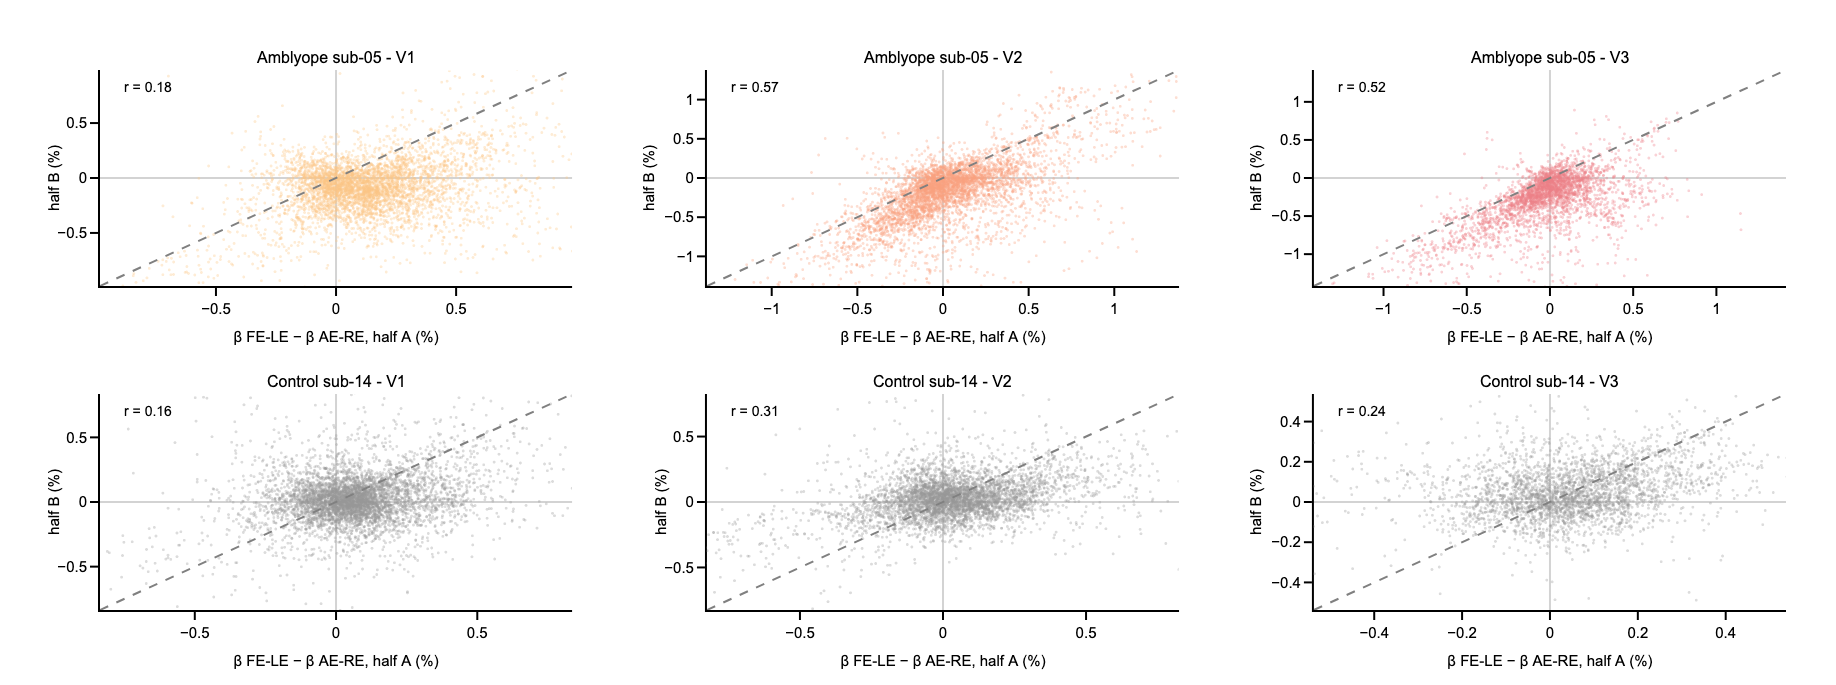

In [12]:
# Figure A: split-half maps of representative subjects (as Nasr Fig. 6)
early = ['V1', 'V2', 'V3']
mean_r = df_sh[(df_sh.split == 'interleaved') & df_sh.roi.isin(early)].groupby(['group', 'subject']).r_true.mean()
examples = {g: (mean_r[g] - mean_r[g].median()).abs().idxmin() for g in groups}
print('Representative subjects:', examples)

fig = make_subplots(rows=2, cols=3, horizontal_spacing=0.08, vertical_spacing=0.2,
                    subplot_titles=['{} {} - {}'.format(group_labels[g][:-1], examples[g], roi) for g in groups for roi in early])
for r_i, group in enumerate(groups, start=1):
    sv = sh_vertex[examples[group]]
    for c_i, roi in enumerate(early, start=1):
        m = sv['keep'] & (sv['roi'] == roi) & np.isfinite(sv['d_A']) & np.isfinite(sv['d_B'])
        x_v, y_v = sv['d_A'][m], sv['d_B'][m]
        lim = np.nanpercentile(np.abs(np.concatenate([x_v, y_v])), 99)
        n = (r_i - 1) * 3 + c_i
        xref, yref = 'x{}'.format('' if n == 1 else n), 'y{}'.format('' if n == 1 else n)
        fig.add_shape(type='line', x0=-lim, x1=lim, y0=-lim, y1=lim, xref=xref, yref=yref, line=dict(color='grey', dash='dash'))
        fig.add_trace(go.Scattergl(x=x_v, y=y_v, mode='markers', showlegend=False,
                                   marker=dict(size=3, opacity=0.35, color=roi_colors_rgb[roi] if group == 'patient' else ctrl_color)),
                      row=r_i, col=c_i)
        fig.add_annotation(x=0.04, y=0.97, xref='{} domain'.format(xref), yref='{} domain'.format(yref), xanchor='left', yanchor='top',
                           text='r = {:.2f}'.format(stats.spearmanr(x_v, y_v).correlation), showarrow=False, font=dict(size=14))
        fig.update_xaxes(range=[-lim, lim], row=r_i, col=c_i)
        fig.update_yaxes(range=[-lim, lim], row=r_i, col=c_i)
fig.update_xaxes(title_text='β FE-LE − β AE-RE, half A (%)', showline=True, zeroline=True, zerolinecolor='lightgrey')
fig.update_yaxes(title_text='half B (%)', showline=True, zeroline=True, zerolinecolor='lightgrey')
fig.update_layout(template=fig_template, height=2 * rois_plot_height * 1.4 + fig_margin[1] + fig_margin[3],
                  width=3 * rois_plot_height * 1.4 + fig_margin[0] + fig_margin[2],
                  margin_l=fig_margin[0], margin_t=fig_margin[1] + 20, margin_r=fig_margin[2], margin_b=fig_margin[3])
fig.show()
fig.write_image('{}/od_q5_A_split_half_maps.pdf'.format(fig_dir))

**Figure A (group):** the same test for every subject. For each subject and ROI, Spearman r across vertices between the β_FE − β_AE maps of half A and half B (interleaved split, true eyes), i.e. the r of the example scatter plots above, computed for all subjects. Bars = median, error bars = 25-75 %, one dot per subject. Stars: r > 0 (Wilcoxon one-sided, FDR over the 8 ROIs, per group).

      median_r               n               p           p_fdr        
group  control patient control patient control patient control patient
roi                                                                   
LO1      0.136   0.257       8      12   0.273   0.008   0.365   0.011
LO2      0.117   0.067       8      12   0.074   0.170   0.148   0.170
V1       0.191   0.293       8      12   0.039   0.002   0.104   0.005
V2       0.322   0.439       8      12   0.004   0.002   0.031   0.005
V3       0.194   0.514       8      12   0.012   0.001   0.047   0.005
V3A     -0.015   0.375       8      12   0.527   0.006   0.603   0.010
V3B     -0.064   0.194       8      12   0.680   0.039   0.680   0.044
V4       0.137   0.416       8      12   0.098   0.002   0.156   0.005


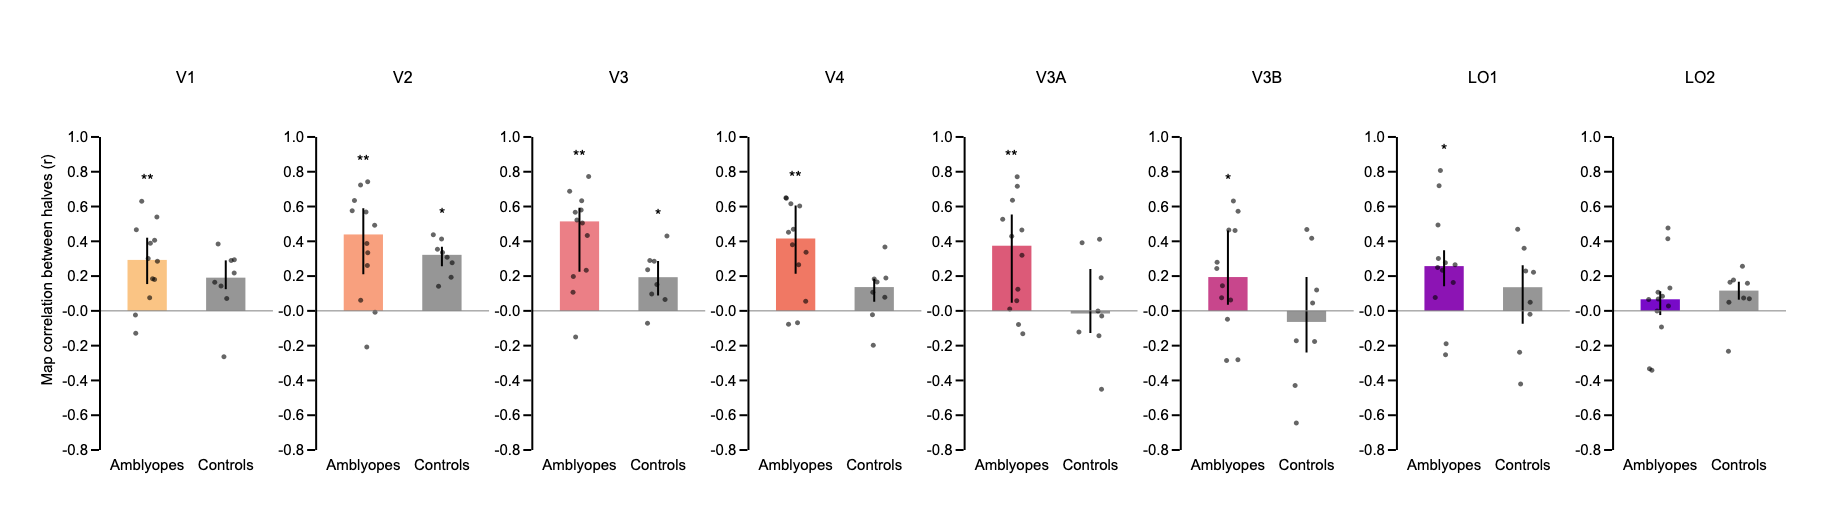

In [13]:
# Figure A (group): map correlation between the halves of the interleaved split, every subject
df_a = df_sh[df_sh.split == 'interleaved']
rows = []
for roi in rois_to_keep:
    for group in groups:
        v = df_a[(df_a.roi == roi) & (df_a.group == group)].r_true.dropna()
        rows.append({'roi': roi, 'group': group, 'median_r': v.median(), 'n': len(v),
                     'p': stats.wilcoxon(v, alternative='greater').pvalue})
a_stats = pd.DataFrame(rows)
a_stats['p_fdr'] = a_stats.groupby('group').p.transform(bh_fdr)
a_stats = a_stats.set_index(['group', 'roi'])
print(a_stats.round(3).unstack('group').to_string())

rng = np.random.default_rng(0)
w = 0.5
r_ticks = nice_ticks(df_a.r_true, 0.2)
y_step = (r_ticks[-1] - r_ticks[0]) * 0.05
fig = make_subplots(rows=1, cols=cols, subplot_titles=rois_to_keep, horizontal_spacing=hor_spacing)
for col_idx, roi in enumerate(rois_to_keep, start=1):
    for g_i, group in enumerate(groups):
        v = df_a[(df_a.roi == roi) & (df_a.group == group)].r_true.dropna()
        med, p25, p75 = v.median(), np.percentile(v, 25), np.percentile(v, 75)
        fig.add_trace(go.Bar(x=[g_i], y=[med], width=w, showlegend=False,
                             marker=dict(color=roi_colors_rgb[roi] if group == 'patient' else ctrl_color),
                             error_y=dict(type='data', array=[p75 - med], arrayminus=[med - p25], thickness=2, width=0, color='black')),
                      row=1, col=col_idx)
        fig.add_trace(go.Scatter(x=g_i + rng.uniform(-w * 0.3, w * 0.3, len(v)), y=v, mode='markers', showlegend=False,
                                 marker=dict(size=5, color='rgba(0,0,0,0.6)')), row=1, col=col_idx)
        fig.add_annotation(x=g_i, y=max(v.max(), 0) + y_step / 2, yanchor='bottom', showarrow=False, font=dict(size=16),
                           text=stars(a_stats.loc[(group, roi), 'p_fdr']), row=1, col=col_idx)
    xref, yref = 'x{}'.format('' if col_idx == 1 else col_idx), 'y{}'.format('' if col_idx == 1 else col_idx)
    fig.add_shape(type='line', x0=0, x1=1, y0=0, y1=0, xref='{} domain'.format(xref), yref=yref, line=dict(color='grey', width=1))
    fig.add_shape(type='line', x0=0, x1=0, y0=r_ticks[0], y1=r_ticks[-1], xref='{} domain'.format(xref), yref=yref,
                  line=dict(color=template_specs['axes_color'], width=template_specs['axes_width']))
fig.update_xaxes(showline=True, ticklen=0, linecolor='rgba(255,255,255,0)', tickangle=0, range=[-0.6, 1.6],
                 tickvals=[0, 1], ticktext=[group_labels[g] for g in groups])
fig.update_yaxes(showline=False, range=[r_ticks[0], r_ticks[-1] + 3 * y_step], tickvals=r_ticks,
                 ticktext=['{:.1f}'.format(t) for t in r_ticks])
fig.update_yaxes(title_text='Map correlation between halves (r)', row=1, col=1)
fig.update_layout(template=fig_template, height=fig_height, width=fig_width,
                  margin_l=fig_margin[0], margin_t=fig_margin[1] + 40, margin_r=fig_margin[2], margin_b=fig_margin[3])
fig.show()
fig.write_image('{}/od_q5_A_group_map_correlation.pdf'.format(fig_dir))

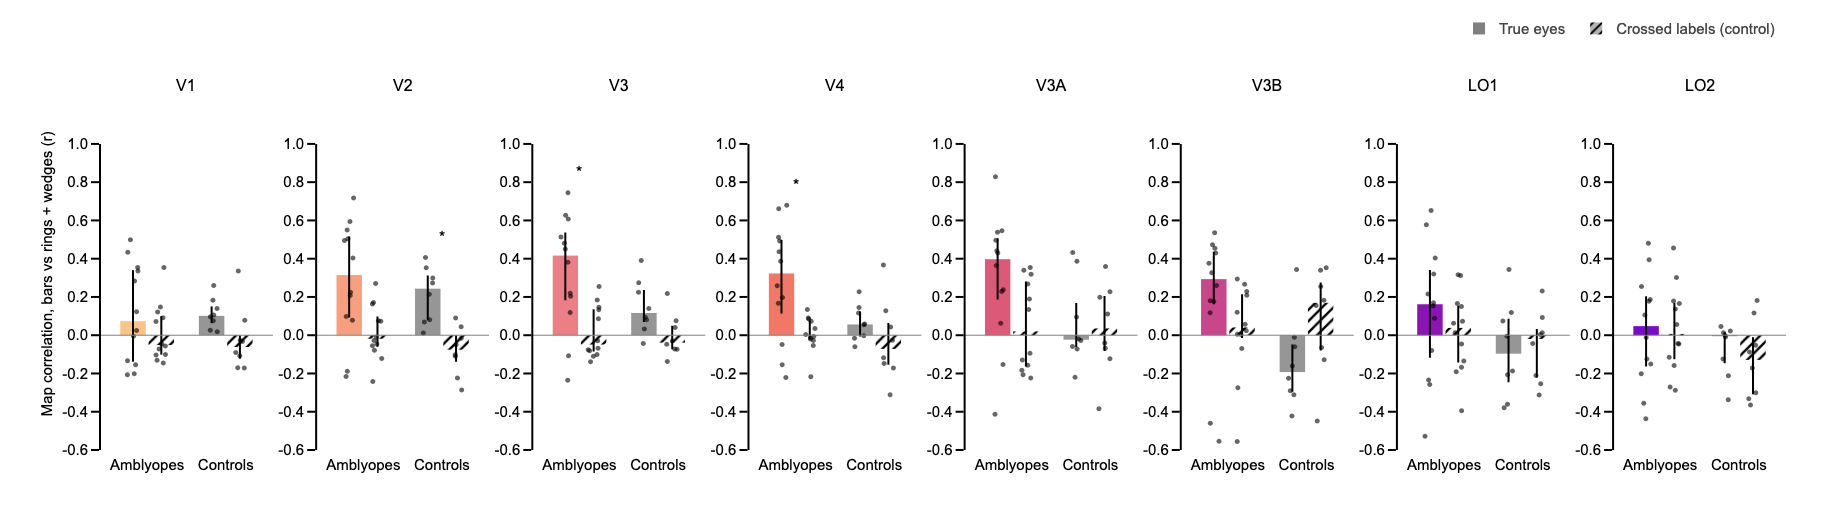

In [14]:
# Figure B: map correlation between halves (stimulus split), true eyes vs crossed labels
df_b = df_sh[df_sh.split == 'stimulus']
rng = np.random.default_rng(0)
conds = [('r_true', '', 'True eyes'), ('r_crossed', '/', 'Crossed labels (control)')]
w = 0.36
r_ticks = nice_ticks(df_b[['r_true', 'r_crossed']].values.ravel(), 0.2)
y_step = (r_ticks[-1] - r_ticks[0]) * 0.05
fig = make_subplots(rows=1, cols=cols, subplot_titles=rois_to_keep, horizontal_spacing=hor_spacing)
for col_idx, roi in enumerate(rois_to_keep, start=1):
    for g_i, group in enumerate(groups):
        dg = df_b[(df_b.roi == roi) & (df_b.group == group)]
        color = roi_colors_rgb[roi] if group == 'patient' else ctrl_color
        for (value, pattern, _), off in zip(conds, [-w / 2, w / 2]):
            v = dg[value].dropna()
            med, p25, p75 = v.median(), np.percentile(v, 25), np.percentile(v, 75)
            fig.add_trace(go.Bar(x=[g_i + off], y=[med], width=w * 0.9, showlegend=False,
                                 marker=dict(color=color, pattern=dict(shape=pattern, fgcolor='rgba(0,0,0,1)', bgcolor='rgba(0,0,0,0)', size=8)),
                                 error_y=dict(type='data', array=[p75 - med], arrayminus=[med - p25], thickness=2, width=0, color='black')),
                          row=1, col=col_idx)
            fig.add_trace(go.Scatter(x=g_i + off + rng.uniform(-w * 0.2, w * 0.2, len(v)), y=v, mode='markers', showlegend=False,
                                     marker=dict(size=5, color='rgba(0,0,0,0.6)')), row=1, col=col_idx)
        top = max(dg.r_true.max(), dg.r_crossed.max(), 0)
        fig.add_annotation(x=g_i, y=top + y_step / 2, yanchor='bottom', showarrow=False, font=dict(size=16),
                           text=stars(sh_stats.loc[(group, roi), 'p_true_vs_crossed_fdr']), row=1, col=col_idx)
    xref, yref = 'x{}'.format('' if col_idx == 1 else col_idx), 'y{}'.format('' if col_idx == 1 else col_idx)
    fig.add_shape(type='line', x0=0, x1=1, y0=0, y1=0, xref='{} domain'.format(xref), yref=yref, line=dict(color='grey', width=1))
    fig.add_shape(type='line', x0=0, x1=0, y0=r_ticks[0], y1=r_ticks[-1], xref='{} domain'.format(xref), yref=yref,
                  line=dict(color=template_specs['axes_color'], width=template_specs['axes_width']))
for _, pattern, label in conds:
    fig.add_trace(go.Bar(x=[None], y=[None], name=label, marker=dict(color='rgba(128,128,128,1)',
                         pattern=dict(shape=pattern, fgcolor='rgba(0,0,0,1)', bgcolor='rgba(0,0,0,0.3)', size=8))), row=1, col=1)
fig.update_xaxes(showline=True, ticklen=0, linecolor='rgba(255,255,255,0)', tickangle=0, range=[-0.6, 1.6],
                 tickvals=[0, 1], ticktext=[group_labels[g] for g in groups])
fig.update_yaxes(showline=False, range=[r_ticks[0], r_ticks[-1] + 3 * y_step], tickvals=r_ticks,
                 ticktext=['{:.1f}'.format(t) for t in r_ticks])
fig.update_yaxes(title_text='Map correlation, bars vs rings + wedges (r)', row=1, col=1)
fig.update_layout(template=fig_template, height=fig_height, width=fig_width,
                  legend=dict(orientation='h', font_family=template_specs['font'], font_size=template_specs['axes_font_size'],
                              x=1, y=1.15, xanchor='right', yanchor='bottom', bgcolor='rgba(0,0,0,0)', itemwidth=30),
                  margin_l=fig_margin[0], margin_t=fig_margin[1] + 40, margin_r=fig_margin[2], margin_b=fig_margin[3])
fig.show()
fig.write_image('{}/od_q5_B_map_correlation_vs_crossed.pdf'.format(fig_dir))

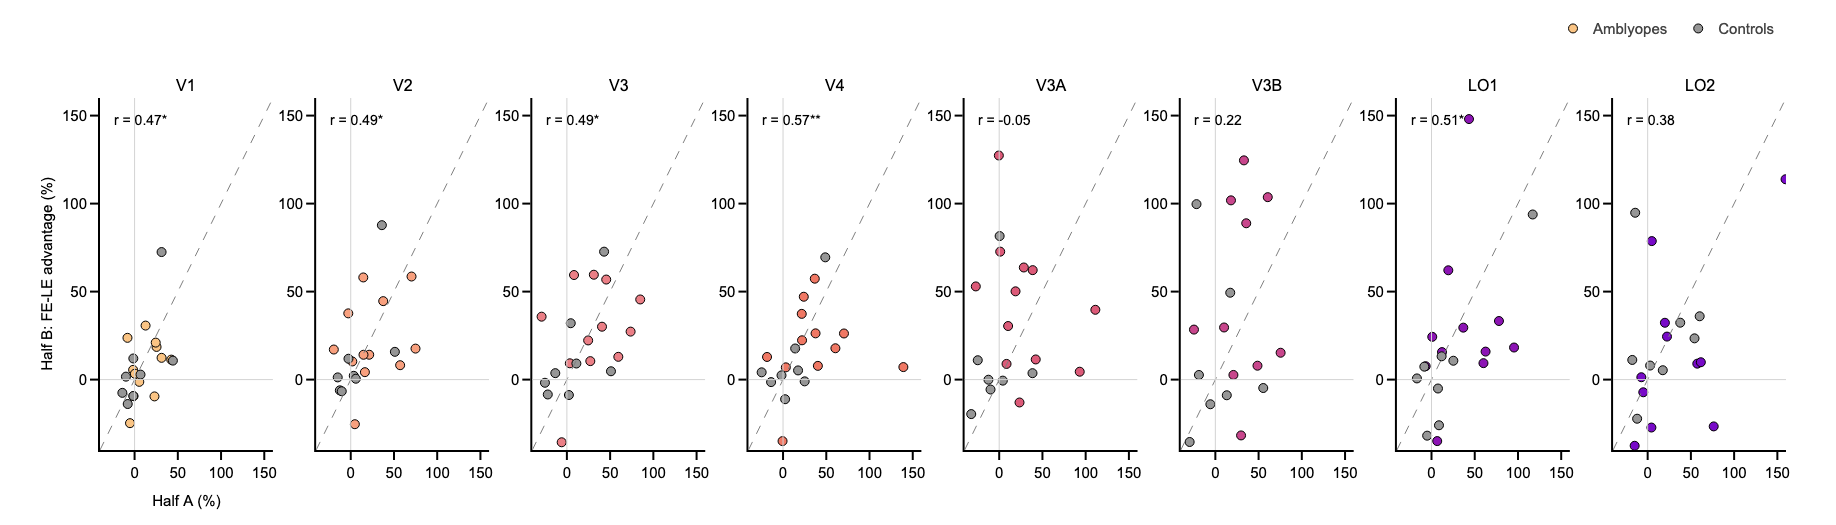

In [15]:
# Figure C: fellow-eye response advantage of each subject, half A vs half B (interleaved split)
df_c = df_sh[df_sh.split == 'interleaved']
vals = df_c[['adv_A', 'adv_B']].values.ravel()
lo, hi = min(-10, np.floor(np.nanpercentile(vals, 1) / 10) * 10), np.ceil(np.nanpercentile(vals, 99) / 10) * 10
fig = make_subplots(rows=1, cols=cols, subplot_titles=rois_to_keep, horizontal_spacing=hor_spacing)
for col_idx, roi in enumerate(rois_to_keep, start=1):
    dr = df_c[df_c.roi == roi].dropna(subset=['adv_A', 'adv_B'])
    xref, yref = 'x{}'.format('' if col_idx == 1 else col_idx), 'y{}'.format('' if col_idx == 1 else col_idx)
    fig.add_shape(type='line', x0=lo, x1=hi, y0=lo, y1=hi, xref=xref, yref=yref, line=dict(color='grey', width=1, dash='dash'))
    fig.add_shape(type='line', x0=lo, x1=hi, y0=0, y1=0, xref=xref, yref=yref, line=dict(color='lightgrey', width=1))
    fig.add_shape(type='line', x0=0, x1=0, y0=lo, y1=hi, xref=xref, yref=yref, line=dict(color='lightgrey', width=1))
    for group in groups:
        dg = dr[dr.group == group]
        fig.add_trace(go.Scatter(x=dg.adv_A, y=dg.adv_B, mode='markers', name=group_labels[group], showlegend=col_idx == 1,
                                 marker=dict(size=9, color=roi_colors_rgb[roi] if group == 'patient' else ctrl_color,
                                             line=dict(width=1, color='black'))), row=1, col=col_idx)
    rho, p = stats.spearmanr(dr.adv_A, dr.adv_B)
    fig.add_annotation(x=0.05, y=0.97, xref='{} domain'.format(xref), yref='{} domain'.format(yref), xanchor='left', yanchor='top',
                       text='r = {:.2f}{}'.format(rho, stars(p)), showarrow=False, font=dict(size=14))
fig.update_xaxes(range=[lo, hi], showline=True, tickangle=0)
fig.update_yaxes(range=[lo, hi], showline=True)
fig.update_xaxes(title_text='Half A (%)', row=1, col=1)
fig.update_yaxes(title_text='Half B: FE-LE advantage (%)', row=1, col=1)
fig.update_layout(template=fig_template, height=fig_height, width=fig_width,
                  legend=dict(orientation='h', font_family=template_specs['font'], font_size=template_specs['axes_font_size'],
                              x=1, y=1.15, xanchor='right', yanchor='bottom', bgcolor='rgba(0,0,0,0)', itemwidth=30),
                  margin_l=fig_margin[0], margin_t=fig_margin[1] + 40, margin_r=fig_margin[2], margin_b=fig_margin[3])
fig.show()
fig.write_image('{}/od_q5_C_advantage_split.pdf'.format(fig_dir))

## Secondary: amblyopes vs controls (exploratory)

The questions above are answered **within** each group. A direct comparison of the groups (Mann-Whitney, FDR) is given for completeness: with 12 vs 8 subjects and a large variability between subjects it has little power (see the mixed model of the previous version: group effect +8.5 % points, 95 % CI [−5.5, 22.5]).

In [16]:
rows = []
for roi in rois_to_keep:
    d = df_subjects[df_subjects.roi == roi]
    row = {'roi': roi}
    for value in ['pref_FE-LE', 'od_index']:
        vp, vc = d[d.group == 'patient'][value].dropna(), d[d.group == 'control'][value].dropna()
        row['diff_{}'.format(value)] = vp.median() - vc.median()
        row['p_{}'.format(value)] = stats.mannwhitneyu(vp, vc).pvalue
    rows.append(row)
between = pd.DataFrame(rows).set_index('roi')
for value in ['pref_FE-LE', 'od_index']:
    between['p_{}_fdr'.format(value)] = bh_fdr(between['p_{}'.format(value)])
between.round(3)

,diff_pref_FE-LE,p_pref_FE-LE,diff_od_index,p_od_index,p_pref_FE-LE_fdr,p_od_index_fdr
roi,,,,,,
V1,6.529,0.473,0.019,0.521,0.540,0.595
V2,6.431,0.427,0.073,0.157,0.540,0.251
V3,13.286,0.270,0.108,0.098,0.432,0.231
V4,13.659,0.135,0.084,0.115,0.360,0.231
V3A,17.591,0.012,0.132,0.016,0.099,0.127
V3B,37.210,0.047,0.123,0.238,0.189,0.317
LO1,21.656,0.238,0.139,0.069,0.432,0.231
LO2,-1.420,0.910,0.021,0.970,0.910,0.970
